# ReturnRadar: E-Commerce Return Risk Prediction and Customer Behavior Analysis

## 1. Project Introduction

E-commerce businesses face challenges when customers return purchased products. Frequent product returns can increase operational costs, affect inventory management, and impact business performance.

ReturnRadar is a machine learning project designed to analyze customer purchasing behavior and predict whether an e-commerce order item is likely to be returned.

## Project Objectives

- Analyze e-commerce customer and order information.
- Identify patterns associated with product returns.
- Perform data cleaning and exploratory data analysis.
- Build machine learning classification models.
- Evaluate model performance using accuracy, precision, recall, F1-score, and ROC-AUC.
- Identify a suitable model for return prediction.

In [7]:

# Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset

df = pd.read_csv("../data/BADS_WS2021_known.csv",na_values=["NA", "", "?"])

print("Dataset loaded successfully!")

print("Dataset shape:", df.shape)

df.head()


Dataset loaded successfully!
Dataset shape: (100000, 14)


,order_item_id,order_date,delivery_date,item_id,item_size,item_color,brand_id,item_price,user_id,user_title,user_dob,user_state,user_reg_date,return
0,1,2016-06-22,2016-06-27,643,38,navy,30,49.90,30822,Mrs,1969-04-17,Saxony,2016-06-23,0
1,2,2016-06-22,NaN,337,152,grey,30,19.95,30822,Mrs,1969-04-17,Saxony,2016-06-23,0
2,3,2016-06-22,2016-06-27,270,xxl,grey,49,79.90,30823,Mrs,1970-04-22,Baden-Wuerttemberg,2015-03-15,1
3,4,2016-06-22,2016-06-27,142,xxl,grey,49,99.90,30823,Mrs,1970-04-22,Baden-Wuerttemberg,2015-03-15,0
4,5,2016-06-22,2016-06-27,561,xxl,grey,3,14.90,30823,Mrs,1970-04-22,Baden-Wuerttemberg,2015-03-15,1


## 2. Dataset Overview

In this step, we examine the dataset structure, column data types, and missing values to understand the quality of the data before preprocessing.

In [8]:
# Check dataset information

df.info()

# Check missing values in each column

print("\nMissing values in each column:")
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 14 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   order_item_id  100000 non-null  int64  
 1   order_date     100000 non-null  object 
 2   delivery_date  90682 non-null   object 
 3   item_id        100000 non-null  int64  
 4   item_size      100000 non-null  object 
 5   item_color     99939 non-null   object 
 6   brand_id       100000 non-null  int64  
 7   item_price     100000 non-null  float64
 8   user_id        100000 non-null  int64  
 9   user_title     100000 non-null  object 
 10  user_dob       91275 non-null   object 
 11  user_state     100000 non-null  object 
 12  user_reg_date  100000 non-null  object 
 13  return         100000 non-null  int64  
dtypes: float64(1), int64(5), object(8)
memory usage: 10.7+ MB

Missing values in each column:
order_item_id       0
order_date          0
delivery_date    9318
item_id  

## 3. Target Variable Distribution

The target variable is `return`.

- 0 represents an order item that was not returned.
- 1 represents an order item that was returned.

We examine the distribution to understand whether the dataset is balanced or imbalanced.

In [9]:
# Count returned and non-returned items

print(df['return'].value_counts())

# Calculate percentages

print("\nTarget variable percentages:")
print(df['return'].value_counts(normalize=True) * 100)

return
0    54182
1    45818
Name: count, dtype: int64

Target variable percentages:
return
0    54.182
1    45.818
Name: proportion, dtype: float64


### 3.1 Target Variable Distribution

This chart shows the distribution of returned and non-returned order items.

**Insight:** The dataset contains 54.18% non-returned items and 45.82% returned items. The classes are relatively balanced, so severe class imbalance is not a major concern.

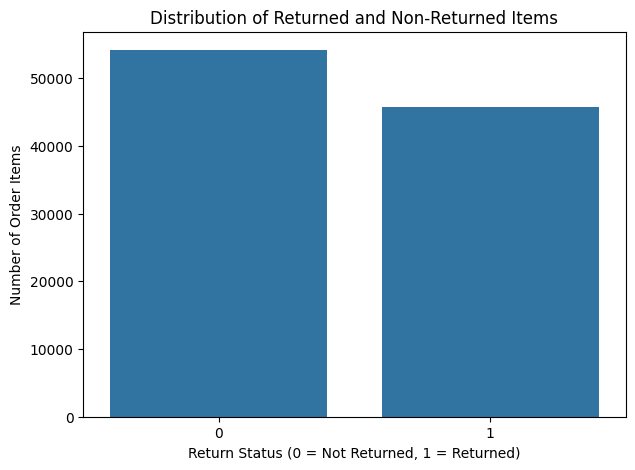

In [10]:
# Visualize target variable distribution

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='return')

plt.title('Distribution of Returned and Non-Returned Items')
plt.xlabel('Return Status (0 = Not Returned, 1 = Returned)')
plt.ylabel('Number of Order Items')

plt.show()

## 4. Duplicate Records

In this step, we check whether the dataset contains duplicate rows. Duplicate records can affect data quality and model evaluation.

In [11]:
# Check complete duplicate rows

print("Number of duplicate rows:", df.duplicated().sum())

# Check duplicate order item IDs

print("Number of duplicate order item IDs:",
      df['order_item_id'].duplicated().sum())

Number of duplicate rows: 0
Number of duplicate order item IDs: 0


## 5. Understanding Dataset Columns

The dataset contains 14 columns describing order items, products, and customers.

In [12]:
print(df.dtypes)     # Display data types of all columns

order_item_id      int64
order_date        object
delivery_date     object
item_id            int64
item_size         object
item_color        object
brand_id           int64
item_price       float64
user_id            int64
user_title        object
user_dob          object
user_state        object
user_reg_date     object
return             int64
dtype: object


In [13]:
# Check the number of unique values in each column

print(df.nunique())

order_item_id    100000
order_date           82
delivery_date       123
item_id            1943
item_size           102
item_color           76
brand_id            135
item_price          252
user_id           19205
user_title            5
user_dob           9247
user_state           16
user_reg_date       573
return                2
dtype: int64


In [14]:
# Display unique values in categorical columns

print("User titles:")
print(df['user_title'].unique())

print("\nCustomer states:")
print(df['user_state'].unique())

print("\nProduct sizes (first 50):")
print(df['item_size'].unique()[:50])

User titles:
['Mrs' 'Family' 'not reported' 'Mr' 'Company']

Customer states:
['Saxony' 'Baden-Wuerttemberg' 'Lower Saxony' 'North Rhine-Westphalia'
 'Hamburg' 'Brandenburg' 'Bavaria' 'Berlin' 'Schleswig-Holstein'
 'Saxony-Anhalt' 'Mecklenburg-Western Pomerania' 'Bremen'
 'Rhineland-Palatinate' 'Hesse' 'Thuringia' 'Saarland']

Product sizes (first 50):
['38' '152' 'xxl' '41' '50' 'l' '48' 'xl' '42' '43' '9' '8+' 'unsized' 'm'
 's' '40' '40+' '6+' '10' '8' '7' '44' '37' '39' '36' '4+' '21' '18' '7+'
 '20' '5+' '46' '6' '19' '4' '5' '35' '31' '38+' '29' '34' '3' '30' '45'
 '22' '24' '41+' '39+' '23' '140']


In [15]:
# Check the 20 most common product sizes

print(df['item_size'].value_counts().head(20))

item_size
l          12347
xl         10979
m          10190
xxl         8966
40          7693
39          6536
38          5611
unsized     5223
42          4969
41          4739
s           3949
37          2289
44          2205
43          1528
36          1372
46          1325
48           978
8            502
6            442
6+           436
Name: count, dtype: int64


## 6. Numerical Feature Analysis

We examine the descriptive statistics of numerical columns to understand their distributions, ranges, and potential unusual values.

In [16]:
df.describe()    # Statistical summary of numerical columns

,order_item_id,item_id,brand_id,item_price,user_id,return
count,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,50000.500000,923.781820,30.149020,65.064695,27169.073960,0.458180
std,28867.657797,702.568822,28.180191,47.991546,14053.417669,0.498251
min,1.000000,1.000000,1.000000,0.000000,9.000000,0.000000
25%,25000.750000,214.000000,5.000000,29.900000,14937.000000,0.000000
50%,50000.500000,812.000000,25.000000,49.900000,31189.000000,0.000000
75%,75000.250000,1581.000000,44.000000,79.900000,38917.250000,1.000000
max,100000.000000,2241.000000,138.000000,999.000000,48241.000000,1.000000


In [17]:
# Examine item price distribution

print("Number of zero-price items:", (df['item_price'] == 0).sum())

print("\nLowest 10 prices:")
print(df['item_price'].nsmallest(10))

print("\nHighest 10 prices:")
print(df['item_price'].nlargest(10))

Number of zero-price items: 396

Lowest 10 prices:
202    0.0
216    0.0
218    0.0
351    0.0
352    0.0
353    0.0
443    0.0
591    0.0
601    0.0
607    0.0
Name: item_price, dtype: float64

Highest 10 prices:
48479    999.00
49210    999.00
65019    999.00
70148    999.00
41329    399.95
55804    399.95
61959    399.95
64678    399.95
66905    399.95
66906    399.95
Name: item_price, dtype: float64


In [18]:
# Compare return rates for zero-price and non-zero-price items

df['price_group'] = np.where(
    df['item_price'] == 0,
    'Zero Price',
    'Non-Zero Price'
)

price_analysis = df.groupby('price_group')['return'].agg(
    ['count', 'mean']
)

price_analysis['return_rate'] = price_analysis['mean'] * 100

print(price_analysis)

                count      mean  return_rate
price_group                                 
Non-Zero Price  99604  0.459530    45.952974
Zero Price        396  0.118687    11.868687


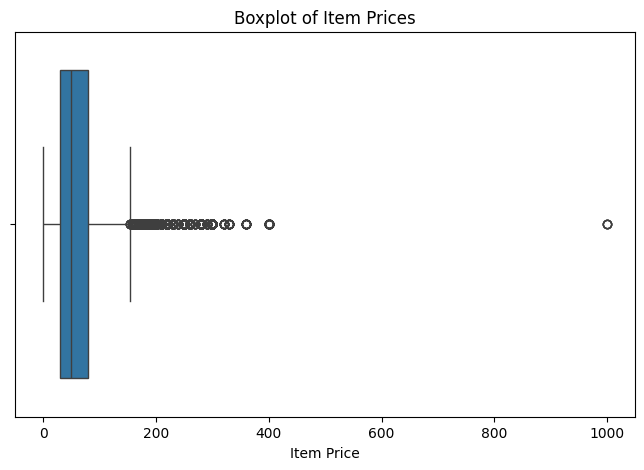

In [19]:
plt.figure(figsize=(8, 5))

sns.boxplot(x=df['item_price'])

plt.title('Boxplot of Item Prices')
plt.xlabel('Item Price')

plt.show()

In [20]:
# Calculate Q1 and Q3

Q1 = df['item_price'].quantile(0.25)
Q3 = df['item_price'].quantile(0.75)

# Calculate IQR

IQR = Q3 - Q1

# Calculate outlier boundaries

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify potential outliers

outliers = df[
    (df['item_price'] < lower_bound) |
    (df['item_price'] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

print("\nNumber of potential outliers:", len(outliers))
print("Outlier percentage:", len(outliers) / len(df) * 100)

Q1: 29.9
Q3: 79.9
IQR: 50.00000000000001
Lower bound: -45.100000000000016
Upper bound: 154.90000000000003

Number of potential outliers: 6226
Outlier percentage: 6.226


In [21]:
# Compare potential outliers with the remaining items

outliers = df[df['item_price'] > upper_bound]
normal_prices = df[df['item_price'] <= upper_bound]

print("Return rate among potential outliers:")
print(outliers['return'].mean() * 100)

print("\nReturn rate among remaining items:")
print(normal_prices['return'].mean() * 100)

Return rate among potential outliers:
58.9624156761966

Return rate among remaining items:
44.945294004734784


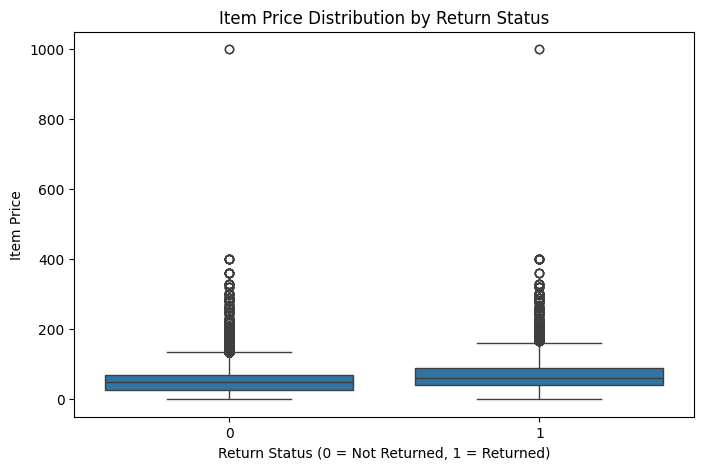

In [22]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='return', y='item_price')

plt.title('Item Price Distribution by Return Status')
plt.xlabel('Return Status (0 = Not Returned, 1 = Returned)')
plt.ylabel('Item Price')

plt.show()

## 7. Date Column Analysis

The dataset contains order, delivery, customer birth, and registration dates. We convert these columns into datetime format to perform date-based analysis and identify invalid date records.

In [23]:
# Convert date columns into datetime format

date_columns = [
    'order_date',
    'delivery_date',
    'user_dob',
    'user_reg_date'
]

for col in date_columns:
    df[col] = pd.to_datetime(df[col], errors='coerce')

# Check updated data types

print(df[date_columns].dtypes)

order_date       datetime64[ns]
delivery_date    datetime64[ns]
user_dob         datetime64[ns]
user_reg_date    datetime64[ns]
dtype: object


In [24]:
# Check minimum and maximum dates

for col in date_columns:
    print(f"\n{col}")
    print("Earliest date:", df[col].min())
    print("Latest date:", df[col].max())


order_date
Earliest date: 2016-06-22 00:00:00
Latest date: 2016-09-11 00:00:00

delivery_date
Earliest date: 1994-12-31 00:00:00
Latest date: 2017-01-24 00:00:00

user_dob
Earliest date: 1900-11-21 00:00:00
Latest date: 2011-07-17 00:00:00

user_reg_date
Earliest date: 2015-02-17 00:00:00
Latest date: 2016-09-12 00:00:00


In [25]:
# Identify delivery dates earlier than order dates

invalid_delivery = df[
    df['delivery_date'].notna() &
    (df['delivery_date'] < df['order_date'])
]

print("Delivery dates before order dates:", len(invalid_delivery))

print("\nExamples:")
print(invalid_delivery[
    ['order_date', 'delivery_date', 'return']
].head(10))

Delivery dates before order dates: 1072

Examples:
     order_date delivery_date  return
286  2016-06-23    1994-12-31       0
287  2016-06-23    1994-12-31       0
288  2016-06-23    1994-12-31       0
788  2016-06-25    1994-12-31       1
789  2016-06-25    1994-12-31       1
790  2016-06-25    1994-12-31       1
952  2016-06-24    1994-12-31       1
2697 2016-06-25    1994-12-31       1
2815 2016-06-25    1994-12-31       1
3138 2016-06-25    1994-12-31       1


In [26]:
# Calculate delivery duration in days

delivery_days = (
    df['delivery_date'] - df['order_date']
).dt.days

# Identify deliveries taking more than 60 days

long_delivery = df[delivery_days > 60]

print("Deliveries taking more than 60 days:", len(long_delivery))

print("\nExamples:")
print(long_delivery[
    ['order_date', 'delivery_date']
].head(10))

Deliveries taking more than 60 days: 1734

Examples:
     order_date delivery_date
889  2016-06-24    2016-08-30
6843 2016-06-27    2016-09-05
6844 2016-06-27    2016-09-05
7339 2016-06-27    2016-09-05
7340 2016-06-27    2016-09-05
7341 2016-06-27    2016-09-05
8408 2016-06-27    2016-09-03
8524 2016-06-27    2016-08-31
8525 2016-06-27    2016-08-31
8526 2016-06-27    2016-08-31


In [27]:
# Calculate valid delivery durations

valid_delivery_days = delivery_days[
    (delivery_days >= 0) &
    (delivery_days <= 60)
]

print("Valid delivery duration statistics:")
print(valid_delivery_days.describe())

Valid delivery duration statistics:
count    87876.000000
mean         6.043243
std          9.329241
min          0.000000
25%          2.000000
50%          3.000000
75%          5.000000
max         60.000000
dtype: float64


In [28]:
invalid_delivery = df[df['delivery_date'] < df['order_date']]

print("Invalid delivery date records:", len(invalid_delivery))

Invalid delivery date records: 1072


### Handling Invalid Delivery Dates

In [29]:
# Replace invalid delivery dates with NaT
df.loc[
    df['delivery_date'] < df['order_date'],
    'delivery_date'
] = pd.NaT

# Verify
print("Invalid delivery dates remaining:",
      (df['delivery_date'] < df['order_date']).sum())

print("Missing delivery dates after cleaning:",
      df['delivery_date'].isnull().sum())

Invalid delivery dates remaining: 0
Missing delivery dates after cleaning: 10390


In [30]:
# Compare return rates for orders with and without delivery dates

df['delivery_status'] = df['delivery_date'].isnull()

print(df.groupby('delivery_status')['return'].agg(['count', 'mean']))

                 count      mean
delivery_status                 
False            89610  0.506807
True             10390  0.038787


In [31]:
registration_after_order = df[df['user_reg_date'] > df['order_date']]

print("Registration dates after order dates:",len(registration_after_order))

Registration dates after order dates: 20255


In [32]:
registration_after_order[['order_date', 'user_reg_date', 'return']].head(10)

,order_date,user_reg_date,return
0,2016-06-22,2016-06-23,0
1,2016-06-22,2016-06-23,0
11,2016-06-22,2016-06-23,0
12,2016-06-22,2016-06-23,0
13,2016-06-22,2016-06-23,0
69,2016-06-23,2016-06-24,1
70,2016-06-23,2016-06-24,0
71,2016-06-23,2016-06-24,1
72,2016-06-23,2016-06-24,0
73,2016-06-23,2016-06-24,1


In [33]:
registration_difference = (df['user_reg_date'] - df['order_date']).dt.days

print("Registration date difference statistics:")
print(registration_difference.describe())

print("\nMost common differences:")
print(registration_difference.value_counts().head(10))

Registration date difference statistics:
count    100000.000000
mean       -273.489420
std         223.034788
min        -572.000000
25%        -503.000000
50%        -261.000000
75%         -23.000000
max           1.000000
dtype: float64

Most common differences:
 1      20255
-496     2424
-498     1744
-497     1381
-499      961
-501      853
-536      836
-500      813
-502      810
-495      805
Name: count, dtype: int64


In [34]:
print("Registration before order:",(registration_difference < 0).sum())

print("Registration on order date:",(registration_difference == 0).sum())

print("Registration after order:",(registration_difference > 0).sum())

Registration before order: 79357
Registration on order date: 388
Registration after order: 20255


In [35]:
print("Earliest date of birth:", df['user_dob'].min())
print("Latest date of birth:", df['user_dob'].max())
print("Missing dates of birth:", df['user_dob'].isnull().sum())

Earliest date of birth: 1900-11-21 00:00:00
Latest date of birth: 2011-07-17 00:00:00
Missing dates of birth: 8725


In [36]:
df['age'] = ((df['order_date'] - df['user_dob']).dt.days / 365.25)

print(df['age'].describe())

count    91275.000000
mean        52.311878
std         11.310492
min          4.944559
25%         46.154689
50%         51.518138
75%         57.226557
max        115.805613
Name: age, dtype: float64


In [37]:
print("Customers below 18:",(df['age'] < 18).sum())

print("Customers above 100:",(df['age'] > 100).sum())

Customers below 18: 42
Customers above 100: 1229


In [38]:
df['age_group'] = '18-100'

df.loc[df['age'] < 18, 'age_group'] = 'Below 18'
df.loc[df['age'] > 100, 'age_group'] = 'Above 100'
df.loc[df['age'].isnull(), 'age_group'] = 'Missing'

print(df.groupby('age_group')['return'].agg(['count', 'mean']))

           count      mean
age_group                 
18-100     90004  0.457957
Above 100   1229  0.497966
Below 18      42  0.476190
Missing     8725  0.454785


In [39]:
print("Missing item colors:", df['item_color'].isnull().sum())

print("\nMost common item colors:")
print(df['item_color'].value_counts().head(10))

Missing item colors: 61

Most common item colors:
item_color
black         18640
blue          10625
brown          8734
grey           8708
red            7264
green          5565
purple         3925
petrol         3670
white          3256
anthracite     2741
Name: count, dtype: int64


In [40]:
print(df['user_title'].value_counts(dropna=False))

user_title
Mrs             95429
Mr               3915
Family            414
Company           128
not reported      114
Name: count, dtype: int64


In [41]:
print(df['user_state'].value_counts())

user_state
North Rhine-Westphalia           22825
Lower Saxony                     15149
Bavaria                          13672
Baden-Wuerttemberg               11981
Hesse                             7586
Schleswig-Holstein                5531
Rhineland-Palatinate              4784
Berlin                            4093
Saxony                            3147
Hamburg                           2535
Brandenburg                       2231
Mecklenburg-Western Pomerania     1640
Thuringia                         1550
Bremen                            1258
Saxony-Anhalt                     1122
Saarland                           896
Name: count, dtype: int64


In [42]:
print("Missing item sizes:", df['item_size'].isnull().sum())

print("\nNumber of unique item sizes:",df['item_size'].nunique())

Missing item sizes: 0

Number of unique item sizes: 102


In [43]:
print("Number of unique item colors:",df['item_color'].nunique())

print("\nMost common colors:")
print(df['item_color'].value_counts().head(15))

Number of unique item colors: 76

Most common colors:
item_color
black         18640
blue          10625
brown          8734
grey           8708
red            7264
green          5565
purple         3925
petrol         3670
white          3256
anthracite     2741
ocher          2321
berry          2092
olive          2078
mocca          1959
denim          1851
Name: count, dtype: int64


In [44]:
print("Unique products:", df['item_id'].nunique())

print("Unique brands:", df['brand_id'].nunique())

Unique products: 1943
Unique brands: 135


In [45]:
print("Earliest order date:", df['order_date'].min())

print("Latest order date:", df['order_date'].max())

print("Number of unique order dates:", df['order_date'].nunique())

Earliest order date: 2016-06-22 00:00:00
Latest order date: 2016-09-11 00:00:00
Number of unique order dates: 82


In [46]:
print("Unique order item IDs:", df['order_item_id'].nunique())

print("Total records:", len(df))

Unique order item IDs: 100000
Total records: 100000


In [47]:
print("Missing item prices:", df['item_price'].isnull().sum())

print("Zero-price items:", (df['item_price'] == 0).sum())

Missing item prices: 0
Zero-price items: 396


### Return Rate Analysis by Item Size

In this step, we examine whether item size is associated with product returns.

In [48]:
size_return_rate = (df.groupby('item_size')['return'].agg(['count', 'mean']).sort_values('count', ascending=False))

print(size_return_rate.head(15))

           count      mean
item_size                 
l          12347  0.452904
xl         10979  0.455688
m          10190  0.459764
xxl         8966  0.429846
40          7693  0.494865
39          6536  0.473225
38          5611  0.453752
unsized     5223  0.276852
42          4969  0.507748
41          4739  0.495885
s           3949  0.468979
37          2289  0.467890
44          2205  0.492517
43          1528  0.482984
36          1372  0.481778


### Insight: Return Rate by Item Size

The return rate varies across different item sizes. Sizes 40, 41, and 42 show relatively higher return rates, while the `unsized` category has a considerably lower return rate.

In [49]:
color_return_rate = (df.groupby('item_color')['return'].agg(['count', 'mean']).sort_values('count', ascending=False))

print(color_return_rate.head(15))

            count      mean
item_color                 
black       18640  0.471459
blue        10625  0.463341
brown        8734  0.485917
grey         8708  0.478525
red          7264  0.435160
green        5565  0.434681
purple       3925  0.420382
petrol       3670  0.465123
white        3256  0.427518
anthracite   2741  0.487778
ocher        2321  0.484705
berry        2092  0.427342
olive        2078  0.460058
mocca        1959  0.473711
denim        1851  0.515937


### Insight: Return Rate by Item Color

The return rate varies across different item colors. Among the 15 most common colors, denim has the highest return rate at approximately 51.59%, while purple has the lowest at approximately 42.04%.

In [50]:
state_return_rate = (df.groupby('user_state')['return'].agg(['count', 'mean']).sort_values('mean', ascending=False))

print(state_return_rate)

                               count      mean
user_state                                    
Mecklenburg-Western Pomerania   1640  0.478659
Saxony                          3147  0.476644
Schleswig-Holstein              5531  0.470439
Bavaria                        13672  0.467525
Lower Saxony                   15149  0.464651
Berlin                          4093  0.462253
Brandenburg                     2231  0.461676
Saxony-Anhalt                   1122  0.459893
Saarland                         896  0.459821
Hesse                           7586  0.459531
Rhineland-Palatinate            4784  0.457358
Baden-Wuerttemberg             11981  0.455555
North Rhine-Westphalia         22825  0.447054
Thuringia                       1550  0.442581
Hamburg                         2535  0.435503
Bremen                          1258  0.416534


### Insight: Return Rate by Customer State

Return rates vary across the 16 German states. Mecklenburg-Western Pomerania has the highest return rate at approximately 47.87%, while Bremen has the lowest at approximately 41.65%.


In [51]:
title_return_rate = (
    df.groupby('user_title')['return'].agg(['count', 'mean']).sort_values('mean', ascending=False))

print(title_return_rate)

              count      mean
user_title                   
Company         128  0.625000
Mrs           95429  0.459808
Mr             3915  0.423244
Family          414  0.396135
not reported    114  0.333333


### Insight: Return Rate by Customer Title

Return rates differ across customer titles. The Company category has the highest return rate at 62.50%, while the not reported category has the lowest at 33.33%.

In [52]:
brand_return_rate = (
    df.groupby('brand_id')['return']
      .agg(['count', 'mean'])
      .sort_values('count', ascending=False)
)

print(brand_return_rate.head(15))

          count      mean
brand_id                 
3         11389  0.366582
1          8381  0.489440
5          5039  0.391546
37         4716  0.431086
11         4236  0.575071
20         2828  0.584866
6          2678  0.489918
17         2579  0.468786
38         2112  0.422348
43         1927  0.542813
42         1920  0.448437
46         1897  0.483395
29         1829  0.489885
28         1781  0.468838
40         1776  0.441441


### Insight: Return Rate by Brand

Return rates vary across the most frequently occurring brands. Brand 20 has the highest return rate at approximately 58.49%, while Brand 3 has the lowest at approximately 36.66%.


In [53]:
product_return_rate = (
    df.groupby('item_id')['return']
      .agg(['count', 'mean'])
      .sort_values('count', ascending=False)
)

print(product_return_rate.head(15))

         count      mean
item_id                 
1415      1046  0.319312
1532       993  0.368580
22         815  0.361963
1401       712  0.290730
100        699  0.587983
32         635  0.266142
1546       624  0.519231
1470       619  0.447496
1607       611  0.543372
1445       534  0.565543
1518       473  0.511628
1404       469  0.266525
498        457  0.424508
242        456  0.618421
255        444  0.400901


### Insight: Return Rate by Product

Return rates vary across frequently ordered products. Product 242 has the highest return rate among the 15 most frequently ordered products at approximately 61.84%, while Product 32 has the lowest at approximately 26.61%.

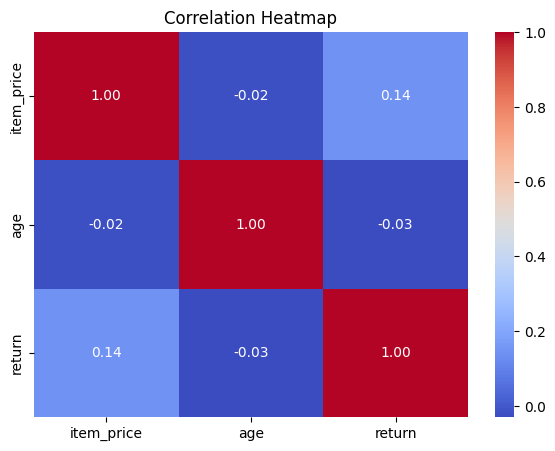

In [54]:
numeric_df = df[['item_price', 'age', 'return']]

plt.figure(figsize=(7, 5))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f')

plt.title('Correlation Heatmap')
plt.show()

### Insight: Correlation Heatmap

The correlation heatmap shows a weak positive correlation (0.14) between item price and returns. Age has a very weak negative correlation (-0.03) with returns.

Item price and age also have almost no correlation (-0.02).


## Exploratory Data Analysis – Summary

In [55]:
# Create a working copy of the dataset
df_clean = df.copy()

print("Original dataset shape:", df.shape)
print("Working dataset shape:", df_clean.shape)

Original dataset shape: (100000, 18)
Working dataset shape: (100000, 18)


In [56]:
# Replace unrealistic ages with missing values
df_clean.loc[
    (df_clean['age'] < 18) | (df_clean['age'] > 100),
    'age'
] = np.nan

print("Missing ages after cleaning:", df_clean['age'].isnull().sum())

Missing ages after cleaning: 9996


In [57]:
df_clean.isnull().sum()

order_item_id          0
order_date             0
delivery_date      10390
item_id                0
item_size              0
item_color            61
brand_id               0
item_price             0
user_id                0
user_title             0
user_dob            8725
user_state             0
user_reg_date          0
return                 0
price_group            0
delivery_status        0
age                 9996
age_group              0
dtype: int64

### Create the delivery features
`delivery_days` (days between order and delivery) and `delivery_missing` (1 = no valid delivery date) are created here and kept as model features.
Invalid delivery dates were already replaced with missing values earlier in the notebook.

In [58]:
# Create delivery features before delivery_date is dropped
df_clean['delivery_days'] = (df_clean['delivery_date'] - df_clean['order_date']).dt.days

df_clean['delivery_missing'] = df_clean['delivery_date'].isna().astype(int)

print("Missing delivery_days:", df_clean['delivery_days'].isnull().sum())
print("\nDelivery missing indicator:")
print(df_clean['delivery_missing'].value_counts())

Missing delivery_days: 10390

Delivery missing indicator:
delivery_missing
0    89610
1    10390
Name: count, dtype: int64


In [59]:
df_clean = df_clean.drop(
    columns=[
        'order_item_id',
        'price_group',
        'delivery_status',
        'age_group',
        'delivery_date',
        'user_dob'
    ]
)

print("Dataset shape:", df_clean.shape)
print(df_clean.columns.tolist())

Dataset shape: (100000, 14)
['order_date', 'item_id', 'item_size', 'item_color', 'brand_id', 'item_price', 'user_id', 'user_title', 'user_state', 'user_reg_date', 'return', 'age', 'delivery_days', 'delivery_missing']


In [60]:
df_clean.isnull().sum()

order_date              0
item_id                 0
item_size               0
item_color             61
brand_id                0
item_price              0
user_id                 0
user_title              0
user_state              0
user_reg_date           0
return                  0
age                  9996
delivery_days       10390
delivery_missing        0
dtype: int64

In [61]:
df_clean['return'].value_counts(normalize=True) * 100

return
0    54.182
1    45.818
Name: proportion, dtype: float64

In [62]:
df_clean['order_month'] = df_clean['order_date'].dt.month
df_clean['order_day_of_week'] = df_clean['order_date'].dt.dayofweek

df_clean[['order_date', 'order_month', 'order_day_of_week']].head()

,order_date,order_month,order_day_of_week
0,2016-06-22,6,2
1,2016-06-22,6,2
2,2016-06-22,6,2
3,2016-06-22,6,2
4,2016-06-22,6,2


In [63]:
df_clean = df_clean.drop(columns=['order_date'])

print(df_clean.shape)
print(df_clean.columns.tolist())

(100000, 15)
['item_id', 'item_size', 'item_color', 'brand_id', 'item_price', 'user_id', 'user_title', 'user_state', 'user_reg_date', 'return', 'age', 'delivery_days', 'delivery_missing', 'order_month', 'order_day_of_week']


In [64]:
registration_days = (df['order_date'] - df['user_reg_date']).dt.days

print(registration_days.describe())

print("Registration after order:",(registration_days < 0).sum())

count    100000.000000
mean        273.489420
std         223.034788
min          -1.000000
25%          23.000000
50%         261.000000
75%         503.000000
max         572.000000
dtype: float64
Registration after order: 20255


In [65]:
df_clean['days_since_registration'] = registration_days

df_clean.loc[
    df_clean['days_since_registration'] < 0,
    'days_since_registration'] = np.nan

print(df_clean['days_since_registration'].describe())
print("Missing tenure values:",df_clean['days_since_registration'].isnull().sum())

count    79745.000000
mean       343.208941
std        195.911346
min          0.000000
25%        153.000000
50%        423.000000
75%        520.000000
max        572.000000
Name: days_since_registration, dtype: float64
Missing tenure values: 20255


In [66]:
df_clean = df_clean.drop(columns=['user_reg_date'])

print("Dataset shape:", df_clean.shape)
print(df_clean.columns.tolist())

Dataset shape: (100000, 15)
['item_id', 'item_size', 'item_color', 'brand_id', 'item_price', 'user_id', 'user_title', 'user_state', 'return', 'age', 'delivery_days', 'delivery_missing', 'order_month', 'order_day_of_week', 'days_since_registration']


### Defining Features (X) and Target Variable (y)

In [67]:
X = df_clean.drop(columns=['return', 'user_id'])
y = df_clean['return']

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nFeature columns:")
print(X.columns.tolist())

Features shape: (100000, 13)
Target shape: (100000,)

Feature columns:
['item_id', 'item_size', 'item_color', 'brand_id', 'item_price', 'user_title', 'user_state', 'age', 'delivery_days', 'delivery_missing', 'order_month', 'order_day_of_week', 'days_since_registration']


### Split the dataset

In [68]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training features: (80000, 13)
Testing features: (20000, 13)

Training target distribution:
return
0    54.1825
1    45.8175
Name: proportion, dtype: float64

Testing target distribution:
return
0    54.18
1    45.82
Name: proportion, dtype: float64


In [69]:
numerical_features = [
    'item_price',
    'age',
    'order_month',
    'order_day_of_week',
    'days_since_registration',
    'delivery_days']

categorical_features = [
    'item_id',
    'item_size',
    'item_color',
    'brand_id',
    'user_title',
    'user_state',
    'delivery_missing']

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

Numerical features: 6
Categorical features: 7


In [70]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numerical_pipeline, numerical_features),
    ('cat', categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [71]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Training data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)

Training data shape: (80000, 2238)
Testing data shape: (20000, 2238)


### Build a model

In [72]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train_processed, y_train)

y_pred_lr = lr_model.predict(X_test_processed)

print("Logistic Regression Accuracy:",
      accuracy_score(y_test, y_pred_lr) * 100)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

Logistic Regression Accuracy: 65.3

Classification Report:
              precision    recall  f1-score   support

           0       0.69      0.65      0.67     10836
           1       0.61      0.65      0.63      9164

    accuracy                           0.65     20000
   macro avg       0.65      0.65      0.65     20000
weighted avg       0.66      0.65      0.65     20000



In [73]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train_processed, y_train)

y_pred_dt = dt_model.predict(X_test_processed)

print("Decision Tree Accuracy:",
      accuracy_score(y_test, y_pred_dt) * 100)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))

Decision Tree Accuracy: 61.42999999999999

Classification Report:
              precision    recall  f1-score   support

           0       0.65      0.64      0.64     10836
           1       0.58      0.59      0.58      9164

    accuracy                           0.61     20000
   macro avg       0.61      0.61      0.61     20000
weighted avg       0.61      0.61      0.61     20000



In [74]:
from sklearn.ensemble import GradientBoostingClassifier

gb_model = GradientBoostingClassifier(
    n_estimators=50,
    max_depth=2,
    learning_rate=0.1,
    random_state=42
)

gb_model.fit(X_train_processed, y_train)

y_pred_gb = gb_model.predict(X_test_processed)

print("Gradient Boosting Accuracy:",
      accuracy_score(y_test, y_pred_gb) * 100)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_gb))

Gradient Boosting Accuracy: 62.69

Classification Report:
              precision    recall  f1-score   support

           0       0.69      0.56      0.62     10836
           1       0.58      0.71      0.63      9164

    accuracy                           0.63     20000
   macro avg       0.63      0.63      0.63     20000
weighted avg       0.64      0.63      0.63     20000



### Random Forest (balanced): validation, threshold tuning and final test evaluation

In [75]:
from sklearn.model_selection import train_test_split

X_rf_train, X_rf_val, y_rf_train, y_rf_val = train_test_split(
    X_train_processed,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("RF training data:", X_rf_train.shape)
print("RF validation data:", X_rf_val.shape)

RF training data: (64000, 2238)
RF validation data: (16000, 2238)


In [76]:
from sklearn.ensemble import RandomForestClassifier

rf_balanced = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf_balanced.fit(X_rf_train, y_rf_train)

print("Random Forest training completed!")

Random Forest training completed!


In [77]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

y_rf_val_prob = rf_balanced.predict_proba(X_rf_val)[:, 1]

# Default threshold = 0.5
y_rf_val_pred = (y_rf_val_prob >= 0.5).astype(int)

print("Random Forest - Validation Results")
print("Accuracy:", accuracy_score(y_rf_val, y_rf_val_pred) * 100)
print("Precision:", precision_score(y_rf_val, y_rf_val_pred))
print("Recall:", recall_score(y_rf_val, y_rf_val_pred))
print("F1 Score:", f1_score(y_rf_val, y_rf_val_pred))
print("ROC-AUC:", roc_auc_score(y_rf_val, y_rf_val_prob))

Random Forest - Validation Results
Accuracy: 62.1625
Precision: 0.5589620463570043
Recall: 0.8256718046651207
F1 Score: 0.6666299559471366
ROC-AUC: 0.6954021229617954


### Model comparison (ROC-AUC)

In [79]:
from sklearn.metrics import roc_auc_score

models = {
    "Logistic Regression": lr_model,
    "Decision Tree": dt_model,
    "Random Forest": rf_balanced,
    "Gradient Boosting": gb_model
}

for name, model in models.items():
    y_probability = model.predict_proba(X_test_processed)[:, 1]
    auc = roc_auc_score(y_test, y_probability)

    print(name, "ROC-AUC:", round(auc, 4))

Logistic Regression ROC-AUC: 0.7153
Decision Tree ROC-AUC: 0.6123
Random Forest ROC-AUC: 0.7021
Gradient Boosting ROC-AUC: 0.6877


In [80]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)

# Predict probabilities on final test data
y_rf_test_prob = rf_balanced.predict_proba(
    X_test_processed
)[:, 1]

# Use threshold 0.50
y_rf_test_pred = (y_rf_test_prob >= 0.50).astype(int)

print("FINAL RANDOM FOREST TEST RESULTS")
print("Accuracy:", accuracy_score(y_test, y_rf_test_pred))
print("Precision:", precision_score(y_test, y_rf_test_pred))
print("Recall:", recall_score(y_test, y_rf_test_pred))
print("F1 Score:", f1_score(y_test, y_rf_test_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_rf_test_prob))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_rf_test_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_rf_test_pred))

FINAL RANDOM FOREST TEST RESULTS
Accuracy: 0.6257
Precision: 0.5620562130177514
Recall: 0.8292230467044959
F1 Score: 0.6699876564979721
ROC-AUC: 0.7020601352025251

Confusion Matrix:
[[4915 5921]
 [1565 7599]]

Classification Report:
              precision    recall  f1-score   support

           0       0.76      0.45      0.57     10836
           1       0.56      0.83      0.67      9164

    accuracy                           0.63     20000
   macro avg       0.66      0.64      0.62     20000
weighted avg       0.67      0.63      0.61     20000



In [81]:
y_rf_val_prob = rf_balanced.predict_proba(
    X_rf_val
)[:, 1]

thresholds = [0.40, 0.45, 0.48, 0.50, 0.52, 0.55]

for threshold in thresholds:

    y_pred = (y_rf_val_prob >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print("Accuracy :", accuracy_score(y_rf_val, y_pred) * 100)
    print("Precision:", precision_score(y_rf_val, y_pred) * 100)
    print("Recall   :", recall_score(y_rf_val, y_pred) * 100)
    print("F1 Score :", f1_score(y_rf_val, y_pred) * 100)


Threshold: 0.4
Accuracy : 57.525000000000006
Precision: 51.930432272497654
Recall   : 98.15850497885691
F1 Score : 67.92524070228431

Threshold: 0.45
Accuracy : 60.2375
Precision: 53.811059545347284
Recall   : 93.31605510844359
F1 Score : 68.25982837756935

Threshold: 0.48
Accuracy : 61.606249999999996
Precision: 55.09521358723624
Recall   : 87.61424089483017
F1 Score : 67.64969192690505

Threshold: 0.5
Accuracy : 62.1625
Precision: 55.89620463570043
Recall   : 82.56718046651207
F1 Score : 66.66299559471366

Threshold: 0.52
Accuracy : 62.41875
Precision: 56.561131023496614
Recall   : 77.49283863047334
F1 Score : 65.39280575539568

Threshold: 0.55
Accuracy : 62.5625
Precision: 61.57831117250907
Recall   : 48.64274996589824
F1 Score : 54.35147081237616


In [82]:
y_rf_test_prob = rf_balanced.predict_proba(
    X_test_processed
)[:, 1]

y_rf_test_pred = (
    y_rf_test_prob >= 0.50
).astype(int)

print("FINAL RANDOM FOREST TEST RESULTS")

print("Accuracy:",
      accuracy_score(y_test, y_rf_test_pred) * 100)

print("Precision:",
      precision_score(y_test, y_rf_test_pred) * 100)

print("Recall:",
      recall_score(y_test, y_rf_test_pred) * 100)

print("F1 Score:",
      f1_score(y_test, y_rf_test_pred) * 100)

print("ROC-AUC:",
      roc_auc_score(y_test, y_rf_test_prob))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_rf_test_pred))

FINAL RANDOM FOREST TEST RESULTS
Accuracy: 62.57
Precision: 56.205621301775146
Recall: 82.92230467044959
F1 Score: 66.9987656497972
ROC-AUC: 0.7020601352025251

Confusion Matrix:
[[4915 5921]
 [1565 7599]]


In [87]:
from sklearn.pipeline import Pipeline

final_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', rf_balanced)
])

print("Complete prediction pipeline created!")

Complete prediction pipeline created!


### Model Dumping:

In [89]:
import os
import joblib


# Create models folder if it doesn't exist
os.makedirs("../models", exist_ok=True)
# Save complete pipeline
joblib.dump(
    final_pipeline,
    "../models/return_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [90]:
import os

model_path = "../models/return_model.pkl"

print("File exists:", os.path.exists(model_path))
print("File size:", round(os.path.getsize(model_path) / (1024 * 1024), 2), "MB")

File exists: True
File size: 4.83 MB


In [93]:

import joblib
import os

# Collect dropdown values from the training data
input_options = {
    "item_id": sorted(X_train["item_id"].dropna().unique().tolist()),
    "brand_id": sorted(X_train["brand_id"].dropna().unique().tolist()),
    "item_size": sorted(X_train["item_size"].dropna().unique().tolist()),
    "item_color": sorted(X_train["item_color"].dropna().unique().tolist()),
    "user_title": sorted(X_train["user_title"].dropna().unique().tolist()),
    "user_state": sorted(X_train["user_state"].dropna().unique().tolist())
}

# Save the options
os.makedirs("../models", exist_ok=True)

joblib.dump(input_options, "../models/input_options.pkl")

print("Input options saved successfully!")

for column, values in input_options.items():
    print(f"{column}: {len(values)} options")


Input options saved successfully!
item_id: 1900 options
brand_id: 133 options
item_size: 101 options
item_color: 75 options
user_title: 5 options
user_state: 16 options
